In [24]:
import os
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
# import matplotlib.ticker as ticker

In [25]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
# pth_out = os.path.join(pth, 'figures', 'CCCA')
# pth_cb = os.path.join(pth_out, 'colorbars')

In [62]:
celltypes = [
    'Epiblast',
    'Posterior Epiblast',
    'Lateral Plate Mesoderm',
    'Neuromesodermal Progenitor',
    'Presomitic Mesoderm',
    'Premigratory Neural Crest',
    'Migratory Neural Crest',
    'Neuroglial Progenitors',
    'Cranial Mesenchyme']

In [63]:
adata = sc.read_h5ad(os.path.join(pth_dev, 'mesencoder.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes)].copy()
adata_3ca = sc.read_h5ad(os.path.join(pth_in, 'mesencoder.h5ad'))
adata_3ca

AnnData object with n_obs × n_vars = 1406087 × 245
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# compute weights (1/n)
grp = adata.obs.groupby('source', observed = True)
w_dict = (grp.size().mean() / grp.size()).to_dict()
adata.obs['w'] = adata.obs.source.map(w_dict).astype(float)

# select training examples
train_frac = .8
ix_train = grp.sample(frac = train_frac).index
msk_train = adata.obs_names.isin(ix_train)
adata.obs['training'] = msk_train.astype(str)

#
src = ['GSE162534', 'GSE229103', 'rRNAModifications']
X_train = adata[msk_train].obs[src]
y_train = (adata[msk_train].obs.source == 'GSE162534')
w_train = adata[msk_train].obs.w

X_val = adata[~msk_train].obs[src]
y_val = (adata[~msk_train].obs.source == 'GSE162534')

f = LogisticRegression(penalty = None).fit(X_train, y_train, w_train)
yhat_train = f.predict(X_train)
yhat_val = f.predict(X_val)

print(roc_auc_score(y_train, f.predict_proba(X_train)[:, 1]))
print(roc_auc_score(y_val, f.predict_proba(X_val)[:, 1]))

0.9767767282125579
0.9788264753614416


In [103]:
X_test = adata_3ca.obs[src]
yhat_test = f.predict_proba(X_test)
adata_3ca.obs[['Branch2', 'Branch1']] = yhat_test * 100

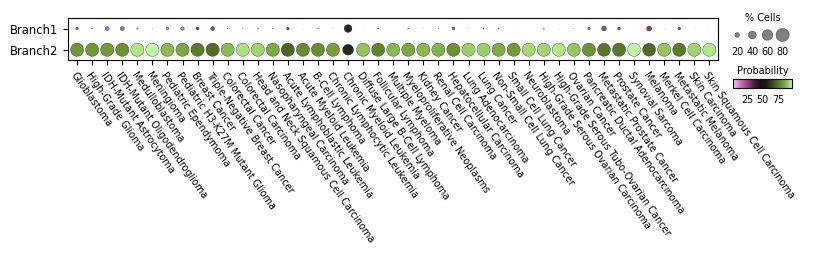

In [121]:
ix = (adata_3ca.obs.groupby(['Category', 'Disease'], observed = True)
      .first().reset_index().Disease)

# signatures dotplot
fs = 7
dp = sc.pl.dotplot(adata_3ca, ['Branch1', 'Branch2'], 'Disease',
                   categories_order = ix,
                   expression_cutoff = 50,
                   dot_max = .8,
                #    vmin = .1, vmax = .2,
                   cmap = 'vanimo',
                   figsize = (9.5, .55),
                   swap_axes = True,
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 90,
         x_padding = .6,
         y_padding = .5)
dp.legend(width = .8)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs, pad = -8)
ax_size.tick_params('x', size = 0, labelsize = fs, pad = 2)
# ax_size.set_xticklabels(['20', '40', '60', '   ≥80'])
cax.set_title('Probability', size = fs, pad = 4.5)
# cax.set_xticks([.25, .75], ['0.1', '0.15', '≥0.2'])
cax.tick_params('x', size = 0, labelsize = fs, pad = 4.5)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([.985 * pos_size.x0,
                      pos_main.y0 + .4 * pos_main.height,
                      pos_size.width,
                      .8 * pos_main.height])

cax.set_position([.985 * pos_color.x0,
                  pos_main.y0 - .65 * pos_main.height,
                  pos_color.width,
                  .2 * pos_main.height])

# ax_main.set_yticklabels([labels_dict[lbl.get_text()] for
#                          lbl in ax_main.get_yticklabels()],
#                         fontsize = fs + .5)

ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        rotation = -55, fontsize = fs,
                        rotation_mode = 'anchor',
                        ha = 'left')

# fn = os.path.join(pth_out, 'signatures.pdf')
# plt.savefig(fn, bbox_inches = 'tight')
plt.show()

In [ ]:
# ix = (adata.obs.groupby(['Category', 'Disease'], observed = True)
#       .first().reset_index().Disease)

# # signatures dotplot
# fs, src = 7, list(labels_dict.keys())
# dp = sc.pl.dotplot(adata, src, 'Disease',
#                    categories_order = ix,
#                    expression_cutoff = .1,
#                    dot_max = .8,
#                    vmin = .1, vmax = .2,
#                    cmap = 'plasma',
#                    figsize = (9.5, .7),
#                    swap_axes = True,
#                    return_fig = True,
#                    show = False)

# dp.style(largest_dot = 90,
#          x_padding = .6,
#          y_padding = .5)
# dp.legend(width = .8)

# ax = dp.get_axes()
# ax_main = ax['mainplot_ax']
# ax_size = ax['size_legend_ax']
# cax = ax['color_legend_ax']

# ax_size.set_title('% Cells', size = fs, pad = -9.5)
# ax_size.tick_params('x', size = 0, labelsize = fs, pad = 2)
# ax_size.set_xticklabels(['20', '40', '60', '   ≥80'])
# cax.set_title('Signature', size = fs, pad = 4.5)
# cax.set_xticks([.1, .15, .2], ['0.1', '0.15', '≥0.2'])
# cax.tick_params('x', size = 0, labelsize = fs, pad = 4.5)

# pos_main = ax_main.get_position()
# pos_size = ax_size.get_position()
# pos_color = cax.get_position()

# ax_size.set_position([.985 * pos_size.x0,
#                       pos_main.y0 + .465 * pos_main.height,
#                       pos_size.width,
#                       .6 * pos_main.height])

# cax.set_position([.985 * pos_color.x0,
#                   pos_main.y0 - .275 * pos_main.height,
#                   pos_color.width,
#                   .15 * pos_main.height])

# ax_main.set_yticklabels([labels_dict[lbl.get_text()] for
#                          lbl in ax_main.get_yticklabels()],
#                         fontsize = fs + .5)

# # ax_main.set_xticklabels(ax_main.get_xticklabels(),
# #                         rotation = -55, fontsize = fs,
# #                         rotation_mode = 'anchor',
# #                         ha = 'left')

# ax_main.set_xticklabels([])
# ax_main.tick_params('x', size = 2.5)

# # fn = os.path.join(pth_out, 'signatures.pdf')
# # plt.savefig(fn, bbox_inches = 'tight')
# plt.show()